# Phase 1 — Data Ingestion, Cleaning & Pipeline Setup

**Project:** Astronomical Object Classification Using Machine Learning  
**Source:** SDSS17 stellar classification dataset (`star_classification.csv`)  
**Target:** `class` (`GALAXY`, `STAR`, `QSO`)  
**Initial predictors:** `u`, `g`, `r`, `i`, `z`  

### Objectives
1. Load and inspect all 18 original columns.
2. Check data types, missing values, sentinel values, duplicate observations and class distribution.
3. Apply explicit, minimal cleaning decisions without destroying scientifically valid data.
4. Export and validate the cleaned 18-column CSV.
5. Define (but **do not fit**) a reusable preprocessing pipeline for later ML phases.
6. Export a machine-readable data quality report.

> **Scope:** Phase 1 does not engineer colour features, scale the entire dataset, or train a model. These activities belong in later phases. Keep the original raw CSV untouched.

## 1. Imports and project paths

Run this notebook either from the project root or from the `notebooks/` directory. The code locates `data/raw/star_classification.csv` automatically. If you downloaded only the notebook, create that project structure and place your original CSV there.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

filename = "star_classification.csv"
search_roots = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]
project_root = next(
    (folder for folder in search_roots if (folder / "data" / "raw" / filename).is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Place star_classification.csv at <project>/data/raw/star_classification.csv "
        "and launch Jupyter from the project root or notebooks/ folder."
    )

raw_path = project_root / "data" / "raw" / filename
processed_path = project_root / "data" / "processed" / "sdss_cleaned.csv"
report_path = project_root / "reports" / "phase1_data_quality_report.json"
processed_path.parent.mkdir(parents=True, exist_ok=True)
report_path.parent.mkdir(parents=True, exist_ok=True)

print("Project root:", project_root.resolve())
print("Raw CSV:", raw_path.resolve())

Project root: C:\Users\daksh\OneDrive\Desktop\ML Project\Astronomical-Object-Classification
Raw CSV: C:\Users\daksh\OneDrive\Desktop\ML Project\Astronomical-Object-Classification\data\raw\star_classification.csv


## 2. Load the original data

`obj_ID` and `spec_obj_ID` are identifiers, not physical numbers. The CSV has rounded scientific-notation forms for some IDs, so reading them as strings prevents *additional* precision loss (but cannot recover digits already missing in the source file).

In [2]:
identifier_dtypes = {"obj_ID": "string", "spec_obj_ID": "string"}
df_raw = pd.read_csv(raw_path, dtype=identifier_dtypes)

print("Original shape:", df_raw.shape)
print("All column names:", df_raw.columns.tolist())
display(df_raw.head(5))

Original shape: (100000, 18)
All column names: ['obj_ID', 'alpha', 'delta', 'u', 'g', 'r', 'i', 'z', 'run_ID', 'rerun_ID', 'cam_col', 'field_ID', 'spec_obj_ID', 'class', 'redshift', 'plate', 'MJD', 'fiber_ID']


,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
0,1.23766E+18,135.689107,32.494632,23.87882,22.27530,20.39501,19.16573,18.79371,3606,301,2,79,6.54378E+18,GALAXY,0.634794,5812,56354,171
1,1.23766E+18,144.826101,31.274185,24.77759,22.83188,22.58444,21.16812,21.61427,4518,301,5,119,1.17601E+19,GALAXY,0.779136,10445,58158,427
2,1.23766E+18,142.188790,35.582444,25.26307,22.66389,20.60976,19.34857,18.94827,3606,301,2,120,5.1522E+18,GALAXY,0.644195,4576,55592,299
3,1.23766E+18,338.741038,-0.402828,22.13682,23.77656,21.61162,20.50454,19.25010,4192,301,3,214,1.03011E+19,GALAXY,0.932346,9149,58039,775
4,1.23768E+18,345.282593,21.183866,19.43718,17.58028,16.49747,15.97711,15.54461,8102,301,3,137,6.89186E+18,GALAXY,0.116123,6121,56187,842


In [3]:
print("Data types:")
print(df_raw.dtypes.to_string())
print("\nClass labels:", sorted(df_raw["class"].dropna().unique().tolist()))
print("\nNumerical summary:")
display(df_raw.describe(include="number").T.round(3))

Data types:
obj_ID         string[python]
alpha                 float64
delta                 float64
u                     float64
g                     float64
r                     float64
i                     float64
z                     float64
run_ID                  int64
rerun_ID                int64
cam_col                 int64
field_ID                int64
spec_obj_ID    string[python]
class                  object
redshift              float64
plate                   int64
MJD                     int64
fiber_ID                int64

Class labels: ['GALAXY', 'QSO', 'STAR']

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
alpha,100000.0,177.629,96.502,0.006,127.518,180.901,233.895,360.000
delta,100000.0,24.135,19.645,-18.785,5.147,23.646,39.902,83.001
u,100000.0,21.980,31.769,-9999.000,20.352,22.179,23.687,32.781
g,100000.0,20.531,31.750,-9999.000,18.965,21.100,22.124,31.602
r,100000.0,19.646,1.855,9.822,18.136,20.125,21.045,29.572
i,100000.0,19.085,1.758,9.470,17.732,19.405,20.396,32.141
z,100000.0,18.669,31.728,-9999.000,17.461,19.005,19.921,29.384
run_ID,100000.0,4481.366,1964.765,109.000,3187.000,4188.000,5326.000,8162.000
rerun_ID,100000.0,301.000,0.000,301.000,301.000,301.000,301.000,301.000
cam_col,100000.0,3.512,1.587,1.000,2.000,4.000,5.000,6.000


## 3. Data dictionary and feature roles

| Group | Columns | Meaning | Initial ML use |
|---|---|---|---|
| Photometric magnitudes | `u`, `g`, `r`, `i`, `z` | Apparent magnitudes in five filters | **Yes** |
| Sky coordinates | `alpha`, `delta` | Right ascension, declination (degrees) | Optional later experiment |
| Imaging metadata | `obj_ID`, `run_ID`, `rerun_ID`, `cam_col`, `field_ID` | Catalog and imaging identifiers | No |
| Spectroscopy metadata | `spec_obj_ID`, `plate`, `MJD`, `fiber_ID` | Observation identifiers | No |
| Spectroscopic measurement | `redshift` | Spectral wavelength shift | **Separate** experiment |
| Target | `class` | STAR, GALAXY, QSO | Prediction label |

**Magnitude reminder:** a smaller magnitude normally indicates a brighter observed source in the relevant filter. Magnitude values are not simply linear light intensities.

## 4. Check missing, non-finite, and encoded missing values

Pandas counts true `NaN` entries, but some surveys use numerical sentinels such as `-9999` for invalid measurements. Inspect the five photometric bands explicitly.

In [4]:
BANDS = ["u", "g", "r", "i", "z"]
EXPECTED_COLUMNS = [
    "obj_ID", "alpha", "delta", "u", "g", "r", "i", "z",
    "run_ID", "rerun_ID", "cam_col", "field_ID", "spec_obj_ID",
    "class", "redshift", "plate", "MJD", "fiber_ID",
]
SENTINEL = -9999.0

assert df_raw.columns.tolist() == EXPECTED_COLUMNS, "Unexpected input schema."

missing_by_column = df_raw.isna().sum()
invalid_by_band = df_raw[BANDS].eq(SENTINEL).sum()
invalid_mask = df_raw[BANDS].eq(SENTINEL).any(axis=1)
nonfinite_by_band = (~np.isfinite(df_raw[BANDS].to_numpy(dtype=float))).sum(axis=0)

print("Null cells:", int(missing_by_column.sum()))
print("Non-finite values per band:", dict(zip(BANDS, map(int, nonfinite_by_band))))
print("-9999 values per band:")
print(invalid_by_band.to_string())
print("Rows with one or more invalid photometric magnitudes:", int(invalid_mask.sum()))
display(df_raw.loc[invalid_mask, BANDS + ["class", "alpha", "delta"]])

Null cells: 0
Non-finite values per band: {'u': 0, 'g': 0, 'r': 0, 'i': 0, 'z': 0}
-9999 values per band:
u    1
g    1
r    0
i    0
z    1
Rows with one or more invalid photometric magnitudes: 1


,u,g,r,i,z,class,alpha,delta
79543,-9999.0,-9999.0,18.1656,18.01675,-9999.0,STAR,224.006526,-0.624304


## 5. Duplicate records, constant columns and identifier caveats

**Do not automatically drop repeated sky positions.** Two catalog rows with the same position may represent separate spectra of one physical source. Exact duplicate CSV rows and duplicated coordinates are different checks.

`obj_ID` and `spec_obj_ID` appear in rounded scientific notation in this exported CSV and must not be trusted as exact source identifiers.

In [5]:
exact_duplicate_count = int(df_raw.duplicated().sum())
coordinate_duplicate_count = int(df_raw.duplicated(subset=["alpha", "delta"]).sum())
plate_mjd_fiber_duplicate_count = int(
    df_raw.duplicated(subset=["plate", "MJD", "fiber_ID"]).sum()
)
constant_columns = [c for c in df_raw if df_raw[c].nunique(dropna=False) == 1]

print("Exact duplicate rows:", exact_duplicate_count)
print("Repeated sky-coordinate pairs:", coordinate_duplicate_count)
print("Repeated plate/MJD/fiber combinations:", plate_mjd_fiber_duplicate_count)
print("Constant columns:", constant_columns)
print("Distinct obj_ID strings:", df_raw["obj_ID"].nunique())
print("Distinct spec_obj_ID strings:", df_raw["spec_obj_ID"].nunique())

repeated_coordinates = df_raw.loc[
    df_raw.duplicated(subset=["alpha", "delta"], keep=False),
    ["alpha", "delta", "u", "g", "r", "i", "z", "class", "plate", "MJD", "fiber_ID"],
]
display(repeated_coordinates)

Exact duplicate rows: 0
Repeated sky-coordinate pairs: 1
Repeated plate/MJD/fiber combinations: 0
Constant columns: ['rerun_ID']
Distinct obj_ID strings: 5
Distinct spec_obj_ID strings: 57192


,alpha,delta,u,g,r,i,z,class,plate,MJD,fiber_ID
62668,34.7496,-0.601931,23.0401,21.71487,21.54097,22.23682,22.60238,GALAXY,405,51816,28
62669,34.7496,-0.601931,23.0401,21.71487,21.54097,22.23682,22.60238,GALAXY,1507,53763,23


## 6. Class distribution — baseline class imbalance

The majority class is **GALAXY**. A naive model that always predicts this category would get around 59.45% accuracy on the original dataset. Therefore, later phases must also report macro F1 and per-class recall.

,count,percent
class,,
GALAXY,59445,59.44
QSO,18961,18.96
STAR,21594,21.59


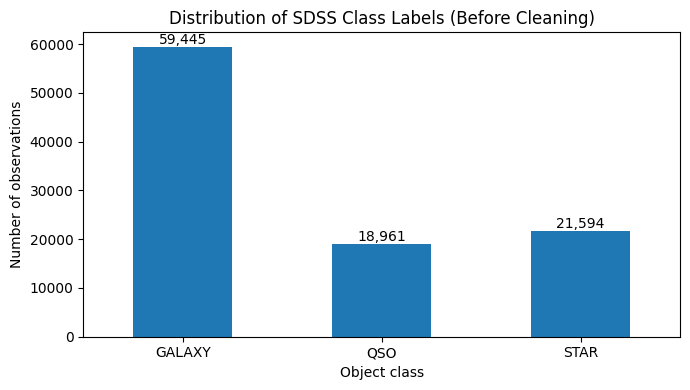

In [6]:
class_counts_before = df_raw["class"].value_counts().sort_index()
class_percent_before = (df_raw["class"].value_counts(normalize=True) * 100).sort_index()
class_overview = pd.DataFrame({
    "count": class_counts_before,
    "percent": class_percent_before.round(2),
})
display(class_overview)

ax = class_counts_before.plot(kind="bar", figsize=(7, 4), rot=0)
ax.set(title="Distribution of SDSS Class Labels (Before Cleaning)",
       xlabel="Object class", ylabel="Number of observations")
for bar in ax.patches:
    ax.annotate(f"{int(bar.get_height()):,}",
                (bar.get_x() + bar.get_width()/2, bar.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.show()

## 7. Cleaning policy and implementation

**Policy for this project:**

1. Remove the one row containing `-9999` in any of the five photometric magnitudes.
2. Do not delete rows solely because sky coordinates repeat or because `redshift` is negative.
3. Keep the original 18-column schema, including metadata, for traceability.
4. Do not engineer colour indices or fit scalers here; they belong in the training workflow.

This is a deliberately minimal and reproducible cleaning decision. For a larger dataset, fitting a missing-value imputer on training folds would also be reasonable.

In [7]:
rows_before = len(df_raw)
df_clean = df_raw.loc[~invalid_mask].copy().reset_index(drop=True)
rows_removed = rows_before - len(df_clean)

assert rows_removed == 1, "Unexpected number of invalid observations."
assert not df_clean[BANDS].eq(SENTINEL).any().any()
assert df_clean.columns.tolist() == EXPECTED_COLUMNS
assert df_clean["class"].isin(["GALAXY", "STAR", "QSO"]).all()
assert df_clean[BANDS].notna().all().all()

print("Original records:", rows_before)
print("Removed records:", rows_removed)
print("Cleaned records:", len(df_clean))
print("Cleaned shape:", df_clean.shape)
print("\nClass distribution after cleaning:")
print(df_clean["class"].value_counts().to_string())

Original records: 100000
Removed records: 1
Cleaned records: 99999
Cleaned shape: (99999, 18)

Class distribution after cleaning:
class
GALAXY    59445
STAR      21593
QSO       18961


## 8. Compare measurements before and after cleaning

An encoded missing value can massively distort the mean and standard deviation. In this dataset, the single invalid row affects three photometric columns.

In [8]:
quality_comparison = pd.DataFrame({
    "raw_mean": df_raw[BANDS].mean(),
    "clean_mean": df_clean[BANDS].mean(),
    "raw_std": df_raw[BANDS].std(),
    "clean_std": df_clean[BANDS].std(),
    "clean_min": df_clean[BANDS].min(),
    "clean_max": df_clean[BANDS].max(),
})
display(quality_comparison.round(4))

,raw_mean,clean_mean,raw_std,clean_std,clean_min,clean_max
u,21.9805,22.0807,31.7693,2.2511,10.9962,32.7814
g,20.5314,20.6316,31.7503,2.0374,10.4982,31.6022
r,19.6458,19.6458,1.8548,1.8548,9.8221,29.5719
i,19.0849,19.0849,1.7579,1.7579,9.4699,32.1415
z,18.6688,18.7690,31.7282,1.7660,9.6123,29.3837


## 9. Export cleaned dataset and validate it after reloading

Always verify that exported files preserve their schema and target values. Do not overwrite the original source file.

In [9]:
df_clean.to_csv(processed_path, index=False)
reloaded = pd.read_csv(processed_path, dtype=identifier_dtypes)

assert reloaded.shape == df_clean.shape
assert reloaded.columns.tolist() == EXPECTED_COLUMNS
assert reloaded["class"].value_counts().to_dict() == df_clean["class"].value_counts().to_dict()
assert not reloaded[BANDS].eq(SENTINEL).any().any()
assert reloaded[BANDS].notna().all().all()

print("Saved:", processed_path.resolve())
print("Verified shape:", reloaded.shape)
print("All export checks passed.")

Saved: C:\Users\daksh\OneDrive\Desktop\ML Project\Astronomical-Object-Classification\data\processed\sdss_cleaned.csv
Verified shape: (99999, 18)
All export checks passed.


## 10. Define a leak-safe preprocessing pipeline (do not fit yet)

An important rule: **never fit a scaler or imputer using the complete dataset before splitting**. We only define the preprocessing pipeline here. Later, in Phase 4, we will use stratified splitting and place this preprocessing inside a model pipeline so it learns parameters from the correct training folds only.

The primary experiment uses the five photometric features. `redshift`, sky coordinates and metadata are excluded from this first feature set.

In [10]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

PRIMARY_FEATURES = BANDS.copy()
TARGET = "class"

numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

X = df_clean[PRIMARY_FEATURES].copy()
y = df_clean[TARGET].copy()

print("X dimensions:", X.shape)
print("y dimensions:", y.shape)
print("Preprocessor defined but intentionally NOT fitted:")
print(numeric_preprocessor)

X dimensions: (99999, 5)
y dimensions: (99999,)
Preprocessor defined but intentionally NOT fitted:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])


## 11. Save Phase 1 quality report

The JSON report is a concise evidence trail for your GitHub repository and final presentation.

In [11]:
report = {
    "project": "Astronomical Object Classification Using Machine Learning",
    "phase": 1,
    "raw_rows": int(len(df_raw)),
    "clean_rows": int(len(df_clean)),
    "columns": int(df_raw.shape[1]),
    "missing_cells_before": int(df_raw.isna().sum().sum()),
    "exact_duplicate_rows_before": exact_duplicate_count,
    "duplicate_sky_coordinate_pairs_before": coordinate_duplicate_count,
    "duplicate_plate_mjd_fiber_before": plate_mjd_fiber_duplicate_count,
    "sentinel_value": SENTINEL,
    "invalid_photometric_rows": int(invalid_mask.sum()),
    "invalid_zero_based_row_indices": [int(x) for x in df_raw.index[invalid_mask]],
    "invalid_per_band": {band: int(invalid_by_band[band]) for band in BANDS},
    "constant_columns": constant_columns,
    "original_class_counts": {str(k): int(v) for k, v in df_raw["class"].value_counts().items()},
    "clean_class_counts": {str(k): int(v) for k, v in df_clean["class"].value_counts().items()},
    "primary_features": PRIMARY_FEATURES,
    "target": TARGET,
    "cleaning_decision": "Drop -9999 photometric rows; retain repeated sky positions and negative redshifts.",
}
with report_path.open("w", encoding="utf-8") as handle:
    json.dump(report, handle, indent=2)

print("Saved report:", report_path.resolve())
print(json.dumps(report, indent=2))

Saved report: C:\Users\daksh\OneDrive\Desktop\ML Project\Astronomical-Object-Classification\reports\phase1_data_quality_report.json
{
  "project": "Astronomical Object Classification Using Machine Learning",
  "phase": 1,
  "raw_rows": 100000,
  "clean_rows": 99999,
  "columns": 18,
  "missing_cells_before": 0,
  "exact_duplicate_rows_before": 0,
  "duplicate_sky_coordinate_pairs_before": 1,
  "duplicate_plate_mjd_fiber_before": 0,
  "sentinel_value": -9999.0,
  "invalid_photometric_rows": 1,
  "invalid_zero_based_row_indices": [
    79543
  ],
  "invalid_per_band": {
    "u": 1,
    "g": 1,
    "r": 0,
    "i": 0,
    "z": 1
  },
  "constant_columns": [
    "rerun_ID"
  ],
  "original_class_counts": {
    "GALAXY": 59445,
    "STAR": 21594,
    "QSO": 18961
  },
  "clean_class_counts": {
    "GALAXY": 59445,
    "STAR": 21593,
    "QSO": 18961
  },
  "primary_features": [
    "u",
    "g",
    "r",
    "i",
    "z"
  ],
  "target": "class",
  "cleaning_decision": "Drop -9999 photometr

## 12. Final Phase 1 verification checklist

- [x] Dataset loaded from its original CSV.
- [x] Original structure and column meanings documented.
- [x] Class balance inspected.
- [x] True missing values and hidden sentinel values inspected.
- [x] Exact duplicate and repeated-coordinate checks performed.
- [x] One invalid photometric record removed; repeated spectra retained.
- [x] Cleaned 18-column CSV exported and validated.
- [x] Leak-safe preprocessing **defined** (not fitted).
- [x] JSON data quality report exported.

**Expected shape:** `(99_999, 18)` for the cleaned dataset.  
**Phase 2:** EDA, descriptive statistics, magnitude histograms, class-wise boxplots, colour-colour plots and correlation heatmaps.  
**Phase 4:** Feature engineering, train/test splitting and fitting leak-safe pipelines during model training.